# HW1: Exploratory Analysis of a Music Catalog
Student ID: **113062273**

Run all cells from a fresh Python kernel, with `tracks.csv` beside this notebook.
If absent, the file is downloaded from the assignment's starter URL. All analysis
uses this file alone. Tables and figures are saved under `HW1_results_113062273/`.
The original starter and pre-registration report are preserved.

This notebook contains executable analysis and technical method notes. The final
report's reasoning must be written by the student, as required by Spec Rule 3.
Pre-registration RMSE values are transcribed unchanged: energy **0.12**, popularity **18**.

In [1]:
%pip install -q numpy==2.2.6 pandas==2.3.3 scipy==1.16.1 matplotlib==3.10.5 scikit-learn==1.7.1 threadpoolctl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
import sys, json, hashlib, platform, urllib.request, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, root_mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from threadpoolctl import threadpool_limits

SEED = 113062273
PRE_RMSE = {'energy': 0.12, 'popularity': 18.0}
rng = np.random.default_rng(SEED)
thread_limit = threadpool_limits(limits=2)
OUT = Path('C:\\Users\\chinh\\Desktop\\Machine Learning\\tmp\\last_audit\\k7_candidate\\results')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200,
                     'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

def table(name, frame, show=True):
    frame.to_csv(OUT / (name + '.csv'), index=True, encoding='utf-8-sig')
    if show:
        display(frame.round(6))
    return frame

def figure(name, fig):
    fig.savefig(OUT / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scipy': scipy.__version__,
            'matplotlib': matplotlib.__version__, 'scikit-learn': sklearn.__version__}
print(json.dumps(versions, indent=2))

{
  "python": "3.13.5",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "scipy": "1.16.1",
  "matplotlib": "3.10.5",
  "scikit-learn": "1.7.1"
}


In [3]:
DATA_URL = 'https://github.com/nthu-cs-hmilab/I2ML-2026/releases/download/data/tracks.csv'
LOCAL_PATH = Path('tracks.csv')
if not LOCAL_PATH.exists():
    temporary = LOCAL_PATH.with_suffix('.csv.part')
    urllib.request.urlretrieve(DATA_URL, temporary)
    temporary.replace(LOCAL_PATH)
raw = pd.read_csv(LOCAL_PATH)
assert raw.shape == (114000, 20), f'Unexpected assignment dataset shape: {raw.shape}'
AUDIO = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo']
BASE_INPUTS = ['danceability', 'speechiness', 'acousticness', 'instrumentalness',
               'liveness', 'valence', 'loudness', 'tempo', 'key', 'mode', 'time_signature']
CAT = ['key', 'mode', 'time_signature']
NUM = [c for c in BASE_INPUTS if c not in CAT]
UNIT = ['danceability', 'energy', 'speechiness', 'acousticness',
        'instrumentalness', 'liveness', 'valence']
manifest = {'student_id': str(SEED), 'data_url': DATA_URL,
            'dataset_sha256': hashlib.sha256(LOCAL_PATH.read_bytes()).hexdigest(),
            'raw_shape': list(raw.shape), 'versions': versions, 'seed': SEED,
            'preregistered_rmse': PRE_RMSE}
print('Dataset:', raw.shape, 'SHA256:', manifest['dataset_sha256'])
display(raw.head(3))

Dataset: (114000, 20) SHA256: db8cd3670209db33285dbfa7ad08dc05446219e9c430e7750abfd17e99297c42


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,0,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


## Section 3: Raw-data audit and cleaning
Raw rows are deliberately used only for the audit and the explicitly labelled
duplicate-weight sensitivity check. Geometry uses nine continuous audio features;
integer-coded key, mode and time signature are not treated as Euclidean coordinates.
All three are one-hot encoded in regression, including a category for every valid
observed value. Duration, explicit, identifiers and genre are excluded from Q1/Q2/Q4.

In [4]:
missing = raw.isna().sum().to_frame('missing_rows')
table('audit_missing', missing)
table('audit_numeric_summary', raw.select_dtypes(include='number').describe().T)
table('audit_genre_counts_raw', raw.groupby('track_genre').size().to_frame('rows'))
exact_duplicates = raw.duplicated().sum()
id_counts = raw.groupby('track_id').size()
genre_counts = raw.groupby('track_id').track_genre.nunique()
dedup = raw.drop_duplicates().copy()
numeric_payload = AUDIO + CAT + ['popularity', 'duration_ms']
variation = dedup.groupby('track_id')[numeric_payload].nunique(dropna=False)
table('audit_conflicting_columns', variation.gt(1).sum().to_frame('conflicting_track_ids'))
conflict_ids = variation.index[variation[AUDIO + CAT + ['popularity']].gt(1).any(axis=1)]
table('audit_conflict_examples', dedup[dedup.track_id.isin(conflict_ids[:5])]
      [['track_id', 'track_genre', 'popularity', 'energy', 'tempo', 'artists']], show=True)
table('audit_duplicate_distribution', id_counts.value_counts().sort_index().to_frame('track_ids'))

invalid = pd.DataFrame(index=raw.index)
invalid['missing_id'] = raw.track_id.isna() | raw.track_id.fillna('').str.strip().eq('')
invalid['missing_audio_or_target'] = raw[AUDIO + CAT + ['popularity']].isna().any(axis=1)
invalid['nonfinite_audio_or_target'] = ~np.isfinite(raw[AUDIO + CAT + ['popularity']]).all(axis=1)
invalid['unit_interval'] = ((raw[UNIT] < 0) | (raw[UNIT] > 1)).any(axis=1)
invalid['popularity_range'] = ~raw.popularity.between(0, 100)
invalid['duration_nonpositive'] = raw.duration_ms.le(0)
invalid['key_code'] = ~raw.key.isin(range(12))
invalid['mode_code'] = ~raw['mode'].isin([0, 1])
invalid['signature_code'] = ~raw.time_signature.isin([1, 2, 3, 4, 5])
invalid['tempo_nonpositive'] = raw.tempo.le(0)
table('audit_validity', invalid.sum().to_frame('flagged_rows'))
table('audit_musical_codes', pd.concat([raw[c].value_counts().rename(c) for c in CAT], axis=1).fillna(0))
table('audit_sentinel_examples', raw[invalid.signature_code | invalid.tempo_nonpositive]
      [['track_id', 'track_genre', 'energy', 'loudness', 'tempo', 'time_signature']].head(12))
table('audit_popularity_by_id_spread', dedup.groupby('track_id').popularity.agg(['min','max'])
      .assign(spread=lambda x: x['max']-x['min']).query('spread > 0')
      .sort_values('spread', ascending=False).head(20))

,missing_rows
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0
key,0


,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.00000,0.000042,0.0490,1.000


,rows
track_genre,
acoustic,1000
afrobeat,1000
alt-rock,1000
alternative,1000
ambient,1000
...,...
techno,1000
trance,1000
trip-hop,1000


,conflicting_track_ids
danceability,0
energy,0
loudness,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
valence,0
tempo,0
key,0


,track_id,track_genre,popularity,energy,tempo,artists
19042,014SIjoLDG1Ku19c5FlDYh,country,0,0.732,100.410,Creedence Clearwater Revival
32435,04IUJPcxiUuXih8eJIVzGz,electronic,1,0.925,126.976,Tube & Berger;Mat.Joe;Tex Amos
38023,03mHinvLdrdSTd7w4GPXwH,garage,56,0.367,143.698,Arctic Monkeys
39864,04IUJPcxiUuXih8eJIVzGz,german,1,0.925,126.976,Tube & Berger;Mat.Joe;Tex Amos
55776,00YwP3wJWiG8IxAA7OS9lo,indian,47,0.419,147.881,Anupam Roy
56324,00YwP3wJWiG8IxAA7OS9lo,indie-pop,47,0.419,147.881,Anupam Roy
57529,00YwP3wJWiG8IxAA7OS9lo,indie,47,0.419,147.881,Anupam Roy
57783,03mHinvLdrdSTd7w4GPXwH,indie,56,0.367,143.698,Arctic Monkeys
65813,00YwP3wJWiG8IxAA7OS9lo,k-pop,47,0.419,147.881,Anupam Roy
68773,02jLfqc9gMo8PkHEGHY3OT,latino,83,0.576,171.945,Feid


,track_ids
1,73100
2,11712
3,2984
4,1372
5,431
6,117
7,22
8,2
9,1


,flagged_rows
missing_id,0
missing_audio_or_target,0
nonfinite_audio_or_target,0
unit_interval,0
popularity_range,0
duration_nonpositive,1
key_code,0
mode_code,0
signature_code,163
tempo_nonpositive,157


,key,mode,time_signature
7,13245,0.0,0.0
0,13061,41319.0,163.0
2,11644,0.0,0.0
9,11313,0.0,0.0
1,10772,72681.0,973.0
5,9368,0.0,1826.0
11,9282,0.0,0.0
4,9008,0.0,101843.0
6,7921,0.0,0.0
10,7456,0.0,0.0


,track_id,track_genre,energy,loudness,tempo,time_signature
2926,0jdfbvSdaWvxfAlD20TtNc,alt-rock,0.56700,-6.346,138.616,0
4131,59gg6zQhSKGVnkT3hWAY3l,ambient,0.03620,-22.519,0.000,0
4379,4acmzQsAeMJa5sGFSog7fu,ambient,0.04450,-26.440,0.000,0
4664,1Kb2DqjHRvOcT5xeWtz3t5,ambient,0.03230,-23.636,0.000,0
26910,7HSc2wpHlXKIl8SCZK7zsP,disney,0.06070,-28.310,93.948,0
45670,6B9Mgf9smWqxDjA35VD6MK,guitar,0.00108,-30.204,0.000,0
45720,7i5OoyPXtSrqz9jobJfG1F,guitar,0.00129,-29.445,0.000,0
45729,0pTAEdockvKVSq1hhFqk7O,guitar,0.00400,-28.326,0.000,0
45773,1keWmyG6qyBbMagPBdgUKr,guitar,0.02680,-30.100,0.000,0
59221,5BcyxCXrXuw4vsAqAiObWM,iranian,0.57200,-16.286,0.000,0


,min,max,spread
track_id,,,
5hljqZrl0h7RcIhUnOPuve,0,44,44
1UwUhKmFxGKs59xiWO60Sx,0,42,42
0C6dSPCqwKqwos6s1CrDrh,0,42,42
5ygEUpyZy5qtZ1423zymBW,0,41,41
1zx6GSqLYI2ynzAHnPRKBR,0,41,41
4KPi4VNvPOfKqIp1sx19Xf,0,41,41
5fClRRa7P9nPIpstj50veV,0,40,40
0z5x3VmmQ7cyTeOP7VAf3T,0,40,40
42GuKw49pPxNAkIhWGwgFs,0,39,39


,min,max,spread
track_id,,,
5hljqZrl0h7RcIhUnOPuve,0,44,44
1UwUhKmFxGKs59xiWO60Sx,0,42,42
0C6dSPCqwKqwos6s1CrDrh,0,42,42
5ygEUpyZy5qtZ1423zymBW,0,41,41
1zx6GSqLYI2ynzAHnPRKBR,0,41,41
4KPi4VNvPOfKqIp1sx19Xf,0,41,41
5fClRRa7P9nPIpstj50veV,0,40,40
0z5x3VmmQ7cyTeOP7VAf3T,0,40,40
42GuKw49pPxNAkIhWGwgFs,0,39,39


In [5]:
# Deterministic row validity; no thresholds learned from held-out targets.
valid_rows = dedup.loc[~invalid.loc[dedup.index].any(axis=1)].copy()
# Conflicting audio/target measurements cannot be resolved without external data.
# Exclude entire conflicting IDs, retaining a single reliable target definition.
valid_rows = valid_rows.loc[~valid_rows.track_id.isin(conflict_ids)].copy()
valid_rows['track_genre'] = valid_rows.track_genre.fillna('UNKNOWN')
for c in ['artists', 'album_name', 'track_name']:
    valid_rows[c] = valid_rows[c].fillna('')
# Membership table preserves all genre labels, without repeating tracks in PCA or regression.
memberships = valid_rows[['track_id', 'track_genre']].drop_duplicates()
clean = valid_rows.drop_duplicates('track_id').sort_values('track_id').reset_index(drop=True)
assert clean.track_id.is_unique
assert clean[AUDIO + CAT + ['popularity']].notna().all().all()
assert set(memberships.track_id) == set(clean.track_id)
cleaning_flow = pd.DataFrame({
    'stage': ['raw listings', 'remove exact duplicate listings', 'remove invalid/sentinel listings',
              'remove conflicting audio/target IDs', 'one row per track'],
    'rows': [len(raw), len(dedup), len(dedup.loc[~invalid.loc[dedup.index].any(axis=1)]),
             len(valid_rows), len(clean)]}).set_index('stage')
table('cleaning_flow', cleaning_flow)
table('cleaned_genre_membership_counts', memberships.groupby('track_genre').size().to_frame('tracks'))

# Rank is an explicit pipeline choice; report justification must be written by the student.
audit_priorities = pd.DataFrame([
    [1, 'Repeated track IDs / weighting and split leakage',
     int(id_counts.gt(1).sum()), 'IDs repeated',
     'One observation per ID; preserve genre memberships; group related recordings when splitting',
     'Track weighting replaces listing weighting'],
    [2, 'Conflicting audio or popularity for an ID', len(conflict_ids), 'IDs conflicting',
     'Exclude conflicting IDs from all downstream analyses', 'Lose ambiguous tracks and genre coverage'],
    [3, 'Invalid values / undetected tempo or metre', int(invalid.any(axis=1).sum()), 'rows flagged',
     'Drop flagged listings; retain valid rare metre codes and valid zero audio scores',
     'May remove genuine silence or music whose beat is hard to detect'],
    [4, 'Equal-size genre sampling / multiple labels', raw.track_genre.nunique(), 'genre categories',
     'Preserve labels; unique-track geometry; never interpret genre counts as market prevalence',
     'Cannot correct unknown population sampling probabilities'],
    [5, 'Missing string metadata', int(raw[['artists','album_name','track_name']].isna().any(axis=1).sum()),
     'rows with missing metadata', 'Keep valid audio tracks; fill metadata with empty strings',
     'Metadata identity and artist inference weaker for these tracks'],
    [6, 'Integer-coded musical categories', len(CAT), 'categorical columns',
     'Exclude from continuous geometry; one-hot encode for regressions',
     'Geometry does not capture key or metre; encoding does not model tonal relationships'],
], columns=['priority','finding','count','unit','implemented_decision','tradeoff']).set_index('priority')
table('audit_priorities', audit_priorities)
manifest['clean_rows'] = len(clean)
manifest['clean_genre_memberships'] = len(memberships)
manifest['conflicting_ids_excluded'] = len(conflict_ids)

,rows
stage,
raw listings,114000
remove exact duplicate listings,113550
remove invalid/sentinel listings,113386
remove conflicting audio/target IDs,111458
one row per track,88858


,tracks
track_genre,
acoustic,998
afrobeat,996
alt-rock,967
alternative,973
ambient,990
...,...
techno,928
trance,922
trip-hop,989


,finding,count,unit,implemented_decision,tradeoff
priority,,,,,
1,Repeated track IDs / weighting and split leakage,16641,IDs repeated,One observation per ID; preserve genre members...,Track weighting replaces listing weighting
2,Conflicting audio or popularity for an ID,720,IDs conflicting,Exclude conflicting IDs from all downstream an...,Lose ambiguous tracks and genre coverage
3,Invalid values / undetected tempo or metre,164,rows flagged,Drop flagged listings; retain valid rare metre...,May remove genuine silence or music whose beat...
4,Equal-size genre sampling / multiple labels,114,genre categories,Preserve labels; unique-track geometry; never ...,Cannot correct unknown population sampling pro...
5,Missing string metadata,1,rows with missing metadata,Keep valid audio tracks; fill metadata with em...,Metadata identity and artist inference weaker ...
6,Integer-coded musical categories,3,categorical columns,Exclude from continuous geometry; one-hot enco...,Geometry does not capture key or metre; encodi...


## Pre-registration expectations: measurements
Expectation 1: energy/loudness positive association and energy/acousticness negative
association. Expectation 2: genre audio profiles differ. Pearson and Spearman
correlations, genre feature effect sizes and the Section 5 profiles provide evidence.
No significance cutoff or effect-size threshold was specified in the pre-report;
these are descriptive comparisons rather than preregistered hypothesis tests.

In [6]:
expectation_correlations = pd.DataFrame({
    'pearson_with_energy': clean[AUDIO].corr(method='pearson')['energy'],
    'spearman_with_energy': clean[AUDIO].corr(method='spearman')['energy']})
table('expectation1_correlations', expectation_correlations)
genre_audio = memberships.merge(clean[['track_id'] + AUDIO], on='track_id', validate='many_to_one')
genre_profiles = genre_audio.groupby('track_genre')[AUDIO].mean()
genre_weights = genre_audio.groupby('track_genre').size()
effects = []
for c in AUDIO:
    grand = genre_audio[c].mean()
    between = ((genre_profiles[c]-grand)**2 * genre_weights).sum()
    total = ((genre_audio[c]-grand)**2).sum()
    effects.append((c, between / total))
table('expectation2_genre_eta_squared', pd.DataFrame(effects, columns=['feature','eta_squared']).set_index('feature'))
# Eta squared is descriptive: multilabel tracks occur in several groups and are not independent.

,pearson_with_energy,spearman_with_energy
danceability,0.135392,0.047027
energy,1.000000,1.000000
loudness,0.759423,0.753197
speechiness,0.139994,0.348945
acousticness,-0.735283,-0.714382
instrumentalness,-0.178305,-0.040740
liveness,0.194255,0.184674
valence,0.251855,0.202097
tempo,0.249098,0.246782


,eta_squared
feature,
danceability,0.408044
energy,0.454159
loudness,0.447681
speechiness,0.444251
acousticness,0.488265
instrumentalness,0.452132
liveness,0.151099
valence,0.303284
tempo,0.078361


,eta_squared
feature,
danceability,0.408044
energy,0.454159
loudness,0.447681
speechiness,0.444251
acousticness,0.488265
instrumentalness,0.452132
liveness,0.151099
valence,0.303284
tempo,0.078361


## Section 4: PCA
Full cleaned unique-track data; nine continuous audio features, including energy.
The primary sufficiency criterion is 90% cumulative explained variance; 80% and
95% are reported as sensitivity checks. Both PCA fits center the input. Only the
first fit standardizes it. Loadings are eigenvector weights; PC signs are arbitrary.

,standardized_ratio,standardized_cumulative,raw_ratio,raw_cumulative
PC1,0.319376,0.319376,0.971338,0.971338
PC2,0.159912,0.479287,0.028302,0.999640
PC3,0.139254,0.618542,0.000122,0.999762
PC4,0.100806,0.719348,0.000081,0.999843
PC5,0.096487,0.815834,0.000063,0.999906
PC6,0.081868,0.897703,0.000046,0.999952
PC7,0.050933,0.948635,0.000022,0.999974
PC8,0.036061,0.984697,0.000016,0.999990
PC9,0.015303,1.000000,0.000010,1.000000


,standardized_components,raw_components
criterion,,
0.80,5,1
0.90,7,1
0.95,8,1


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
danceability,0.250933,0.565619,-0.102497,-0.307693,0.265330,0.136164,0.624630,0.084856,0.160072
energy,0.507625,-0.282246,0.003075,-0.182271,-0.034240,0.065162,-0.246995,0.161348,0.732778
loudness,0.516283,-0.077078,-0.050892,0.011005,-0.210674,-0.161452,0.029067,0.628471,-0.508458
speechiness,0.095802,0.038151,0.643084,-0.258995,0.506362,-0.455780,-0.178124,-0.041820,-0.105434
acousticness,-0.437627,0.305888,0.216821,0.309527,0.031190,0.002117,-0.099896,0.679637,0.315013
instrumentalness,-0.281902,-0.314290,-0.205502,-0.501783,0.420134,0.451977,-0.152504,0.297700,-0.187235
liveness,0.090887,-0.213236,0.674270,0.115759,-0.177381,0.595310,0.293040,-0.029135,-0.075167
valence,0.295905,0.526380,-0.008840,0.163646,0.126783,0.428100,-0.602300,-0.136550,-0.166589
tempo,0.191877,-0.279507,-0.171396,0.645856,0.634522,0.038206,0.185428,0.003877,0.008690


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
danceability,-0.000249,0.009670,-0.111356,-0.286855,0.294919,-0.171441,0.812229,0.135798,-0.332706
energy,0.002186,0.036439,0.251669,-0.285591,-0.080764,0.293139,-0.293908,0.639074,-0.516253
loudness,0.038693,0.997367,-0.003142,0.052068,0.024697,-0.004179,0.004163,-0.014813,0.013281
speechiness,-0.000005,0.001216,-0.024319,-0.023498,-0.037945,0.170931,0.235040,0.614771,0.731444
acousticness,-0.002542,-0.036730,-0.539891,0.639656,0.382477,0.187538,-0.076690,0.256284,-0.212085
instrumentalness,-0.000548,-0.027722,0.710783,0.238037,0.638581,0.129295,0.024091,-0.070325,0.085604
liveness,0.000021,0.003185,-0.015845,-0.000606,-0.200494,0.877341,0.292451,-0.320359,-0.040696
valence,0.000719,0.014192,-0.355968,-0.605860,0.556936,0.183922,-0.326574,-0.147390,0.183408
tempo,0.999245,-0.038817,-0.001184,0.000731,0.000221,-0.000124,0.000732,-0.000062,-0.000088


,raw_variance,share_of_total_raw_variance,standardized_variance
danceability,0.030766,0.000034,1.000011
energy,0.065535,0.000072,1.000011
loudness,26.938804,0.029607,1.000011
speechiness,0.012897,0.000014,1.000011
acousticness,0.114514,0.000126,1.000011
instrumentalness,0.104686,0.000115,1.000011
liveness,0.037705,0.000041,1.000011
valence,0.068869,0.000076,1.000011
tempo,882.492128,0.969914,1.000011


,projection_variance,largest_eigenvalue
raw,883.787229,883.787229
standardized,2.874415,2.874415


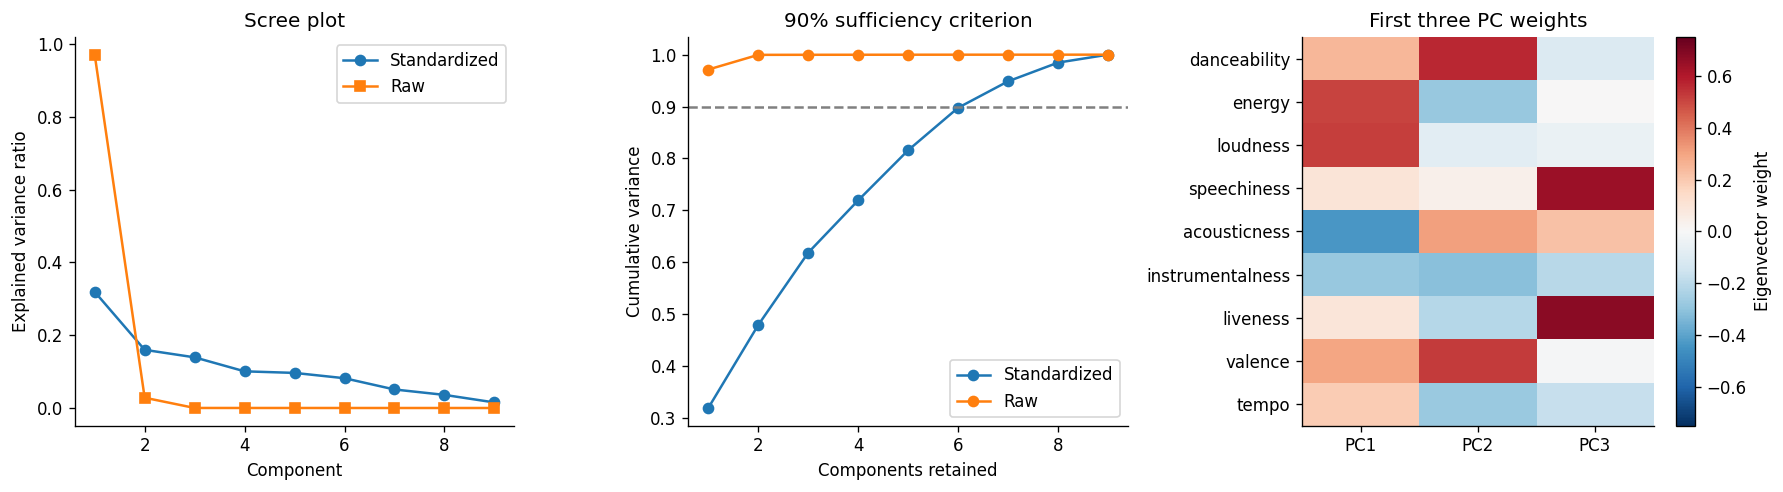

In [7]:
geometry_scaler = StandardScaler()
Z = geometry_scaler.fit_transform(clean[AUDIO])
pca = PCA(svd_solver='full').fit(Z)
pca_raw = PCA(svd_solver='full').fit(clean[AUDIO])
pcs = pca.transform(Z)
pc_names = [f'PC{i+1}' for i in range(len(AUDIO))]
variance_table = pd.DataFrame({
    'standardized_ratio': pca.explained_variance_ratio_,
    'standardized_cumulative': np.cumsum(pca.explained_variance_ratio_),
    'raw_ratio': pca_raw.explained_variance_ratio_,
    'raw_cumulative': np.cumsum(pca_raw.explained_variance_ratio_)}, index=pc_names)
table('pca_variance', variance_table)
dimension_table = pd.DataFrame({
    'criterion': [0.80, 0.90, 0.95],
    'standardized_components': [np.searchsorted(variance_table.standardized_cumulative, t)+1 for t in [0.8,0.9,0.95]],
    'raw_components': [np.searchsorted(variance_table.raw_cumulative, t)+1 for t in [0.8,0.9,0.95]]}).set_index('criterion')
table('pca_dimensions', dimension_table)
loadings = pd.DataFrame(pca.components_.T, index=AUDIO, columns=pc_names)
table('pca_loadings_standardized', loadings)
table('pca_loadings_raw', pd.DataFrame(pca_raw.components_.T, index=AUDIO, columns=pc_names))
cov_raw = np.cov(clean[AUDIO].to_numpy(), rowvar=False, ddof=1)
cov_z = np.cov(Z, rowvar=False, ddof=1)
raw_var = np.diag(cov_raw)
table('pca_feature_variance', pd.DataFrame({'raw_variance': raw_var,
      'share_of_total_raw_variance': raw_var / raw_var.sum(),
      'standardized_variance': np.diag(cov_z)}, index=AUDIO))
objective_checks = pd.DataFrame({
    'projection_variance': [pca_raw.components_[0] @ cov_raw @ pca_raw.components_[0],
                            pca.components_[0] @ cov_z @ pca.components_[0]],
    'largest_eigenvalue': [np.linalg.eigvalsh(cov_raw)[-1], np.linalg.eigvalsh(cov_z)[-1]]},
    index=['raw','standardized'])
table('pca_variance_objective_check', objective_checks)
np.testing.assert_allclose(objective_checks.projection_variance, objective_checks.largest_eigenvalue)
fig, axes = plt.subplots(1,3,figsize=(15,4.2))
x = np.arange(1,len(AUDIO)+1)
axes[0].plot(x,pca.explained_variance_ratio_,'o-',label='Standardized')
axes[0].plot(x,pca_raw.explained_variance_ratio_,'s-',label='Raw')
axes[0].set(xlabel='Component',ylabel='Explained variance ratio',title='Scree plot')
axes[0].legend()
for lab,model in [('Standardized',pca),('Raw',pca_raw)]:
    axes[1].plot(x,np.cumsum(model.explained_variance_ratio_),'o-',label=lab)
axes[1].axhline(.9,color='gray',linestyle='--')
axes[1].set(xlabel='Components retained',ylabel='Cumulative variance',title='90% sufficiency criterion')
axes[1].legend()
im=axes[2].imshow(loadings.iloc[:,:3],aspect='auto',cmap='RdBu_r',vmin=-.75,vmax=.75)
axes[2].set_xticks(range(3),pc_names[:3]);axes[2].set_yticks(range(len(AUDIO)),AUDIO)
axes[2].set_title('First three PC weights')
fig.colorbar(im,ax=axes[2],label='Eigenvector weight')
fig.tight_layout();figure('pca_comparison',fig)

## Section 5.1: Hierarchical genre clustering
Each genre profile is the mean of its unique member tracks. Standardization uses
the unique-track means/SDs from Section 4, keeping one common feature geometry.
All four combinations of Euclidean / city-block distance and average / complete
linkage are compared. Eight genre groups is a fixed comparison cut, not an
estimate of a true number of genres. Group listings, cophenetic correlations,
silhouettes and feature profiles support a student-written preference.

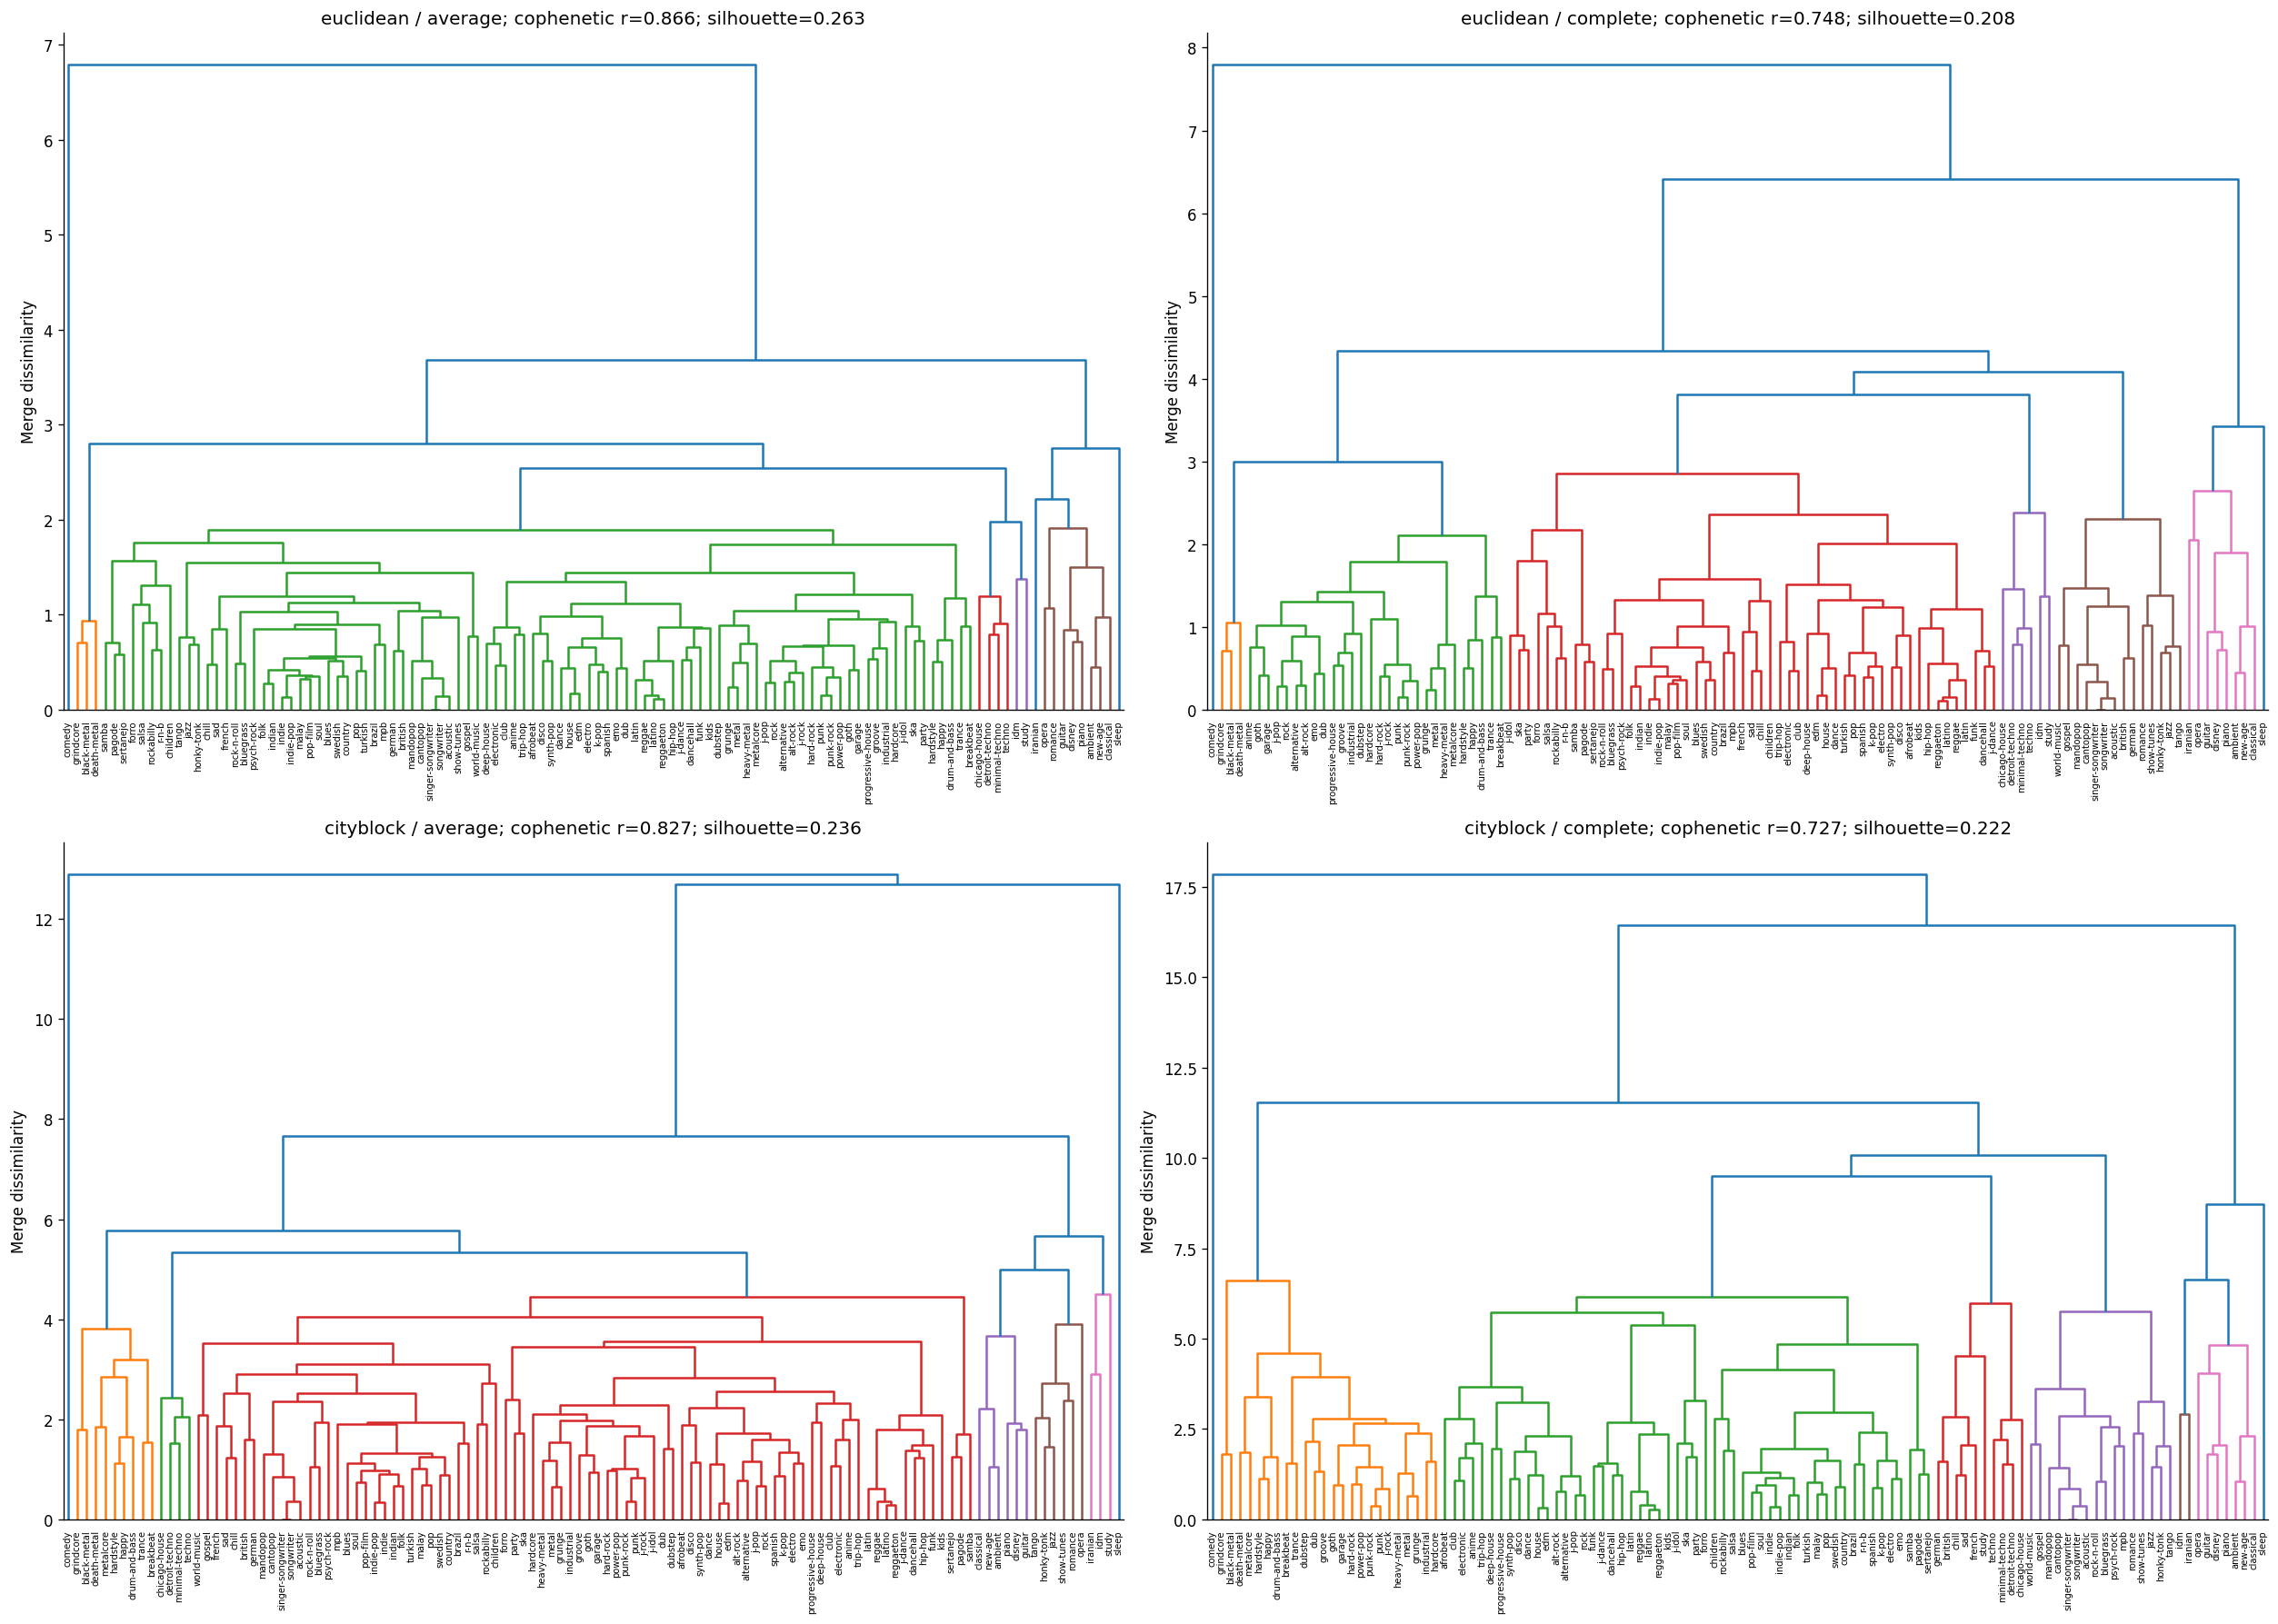

,distance,linkage,cophenetic_r,silhouette
configuration,,,,
euclidean_average,euclidean,average,0.865543,0.263391
euclidean_complete,euclidean,complete,0.748494,0.207913
cityblock_average,cityblock,average,0.827019,0.235743
cityblock_complete,cityblock,complete,0.726662,0.221719


,euclidean_average,euclidean_complete,cityblock_average,cityblock_complete
euclidean_average,1.000000,0.306814,0.707901,0.253538
euclidean_complete,0.306814,1.000000,0.385871,0.629695
cityblock_average,0.707901,0.385871,1.000000,0.355385
cityblock_complete,0.253538,0.629695,0.355385,1.000000


,euclidean_silhouette
euclidean_average,0.263391
euclidean_complete,0.207913
cityblock_average,0.238706
cityblock_complete,0.203163


In [8]:
G = geometry_scaler.transform(genre_profiles[AUDIO])
genre_labels = genre_profiles.index.to_numpy()
GENRE_K = 8
trees, assignments, genre_quality = {}, {}, []
fig,axes=plt.subplots(2,2,figsize=(21,15))
for ax,(metric,method) in zip(axes.flat,itertools.product(['euclidean','cityblock'],['average','complete'])):
    name=f'{metric}_{method}'
    dist=pdist(G,metric=metric)
    tree=linkage(dist,method=method,optimal_ordering=True)
    labs=fcluster(tree,GENRE_K,criterion='maxclust')
    trees[name]=tree;assignments[name]=labs
    coph=cophenet(tree,dist)[0]
    sil=silhouette_score(G,labs,metric=metric)
    genre_quality.append([name,metric,method,coph,sil])
    dendrogram(tree,labels=genre_labels,leaf_rotation=90,leaf_font_size=6,ax=ax,
               color_threshold=tree[-(GENRE_K-1),2])
    ax.set_title(f'{metric} / {method}; cophenetic r={coph:.3f}; silhouette={sil:.3f}')
    ax.set_ylabel('Merge dissimilarity')
fig.tight_layout();figure('genre_dendrograms',fig)
genre_quality=pd.DataFrame(genre_quality,columns=['configuration','distance','linkage','cophenetic_r','silhouette']).set_index('configuration')
table('genre_clustering_quality',genre_quality)
assignments=pd.DataFrame(assignments,index=genre_labels)
table('genre_group_assignments',assignments,show=False)
agreement=pd.DataFrame(index=assignments.columns,columns=assignments.columns,dtype=float)
for a,b in itertools.product(assignments.columns,repeat=2):
    agreement.loc[a,b]=adjusted_rand_score(assignments[a],assignments[b])
table('genre_configuration_ari',agreement)
group_rows=[]
for name in assignments:
    for group in sorted(assignments[name].unique()):
        names=assignments.index[assignments[name].eq(group)]
        group_rows.append([name,group,len(names),', '.join(names)])
table('genre_group_members',pd.DataFrame(group_rows,columns=['configuration','group','n_genres','genres']),show=False)
# A common Euclidean silhouette permits a distance-independent comparison table.
table('genre_quality_common_euclidean',pd.DataFrame({
    'euclidean_silhouette': {name:silhouette_score(G,assignments[name],metric='euclidean') for name in assignments}}))
for name in assignments:
    prof=genre_profiles.assign(group=assignments[name]).groupby('group')[AUDIO].mean()
    table('genre_group_profiles_'+name,prof,show=False)

## Section 5.2: Individual-track k-means
K-means fits all cleaned unique tracks for k=2,...,10, using standardized continuous
audio features and 10 initializations. A fixed uniform sample of 2,000 tracks is
used for every silhouette evaluation because pairwise distances cost O(n squared).
The final k is the maximum sampled silhouette; inertia and its relative reductions
are also reported. This is an operational choice, not proof of discrete musical classes.

k=2: inertia=627300.1, silhouette=0.2633


k=3: inertia=556338.6, silhouette=0.1697


k=4: inertia=501470.8, silhouette=0.1782


k=5: inertia=451775.5, silhouette=0.1814


k=6: inertia=410514.9, silhouette=0.1974


k=7: inertia=373493.2, silhouette=0.2061


k=8: inertia=352584.2, silhouette=0.1847


k=9: inertia=334358.6, silhouette=0.1854


k=10: inertia=320584.2, silhouette=0.1743


,inertia,silhouette,iterations,relative_inertia_reduction
k,,,,
2,627300.060608,0.263265,9,NaN
3,556338.631326,0.169742,10,0.113122
4,501470.762311,0.178210,11,0.098623
5,451775.484598,0.181398,33,0.099099
6,410514.925175,0.197434,19,0.091330
7,373493.193178,0.206058,17,0.090184
8,352584.162301,0.184673,16,0.055982
9,334358.637580,0.185388,41,0.051691
10,320584.242031,0.174322,81,0.041196


Chosen k by elbow and local silhouette peak: 7


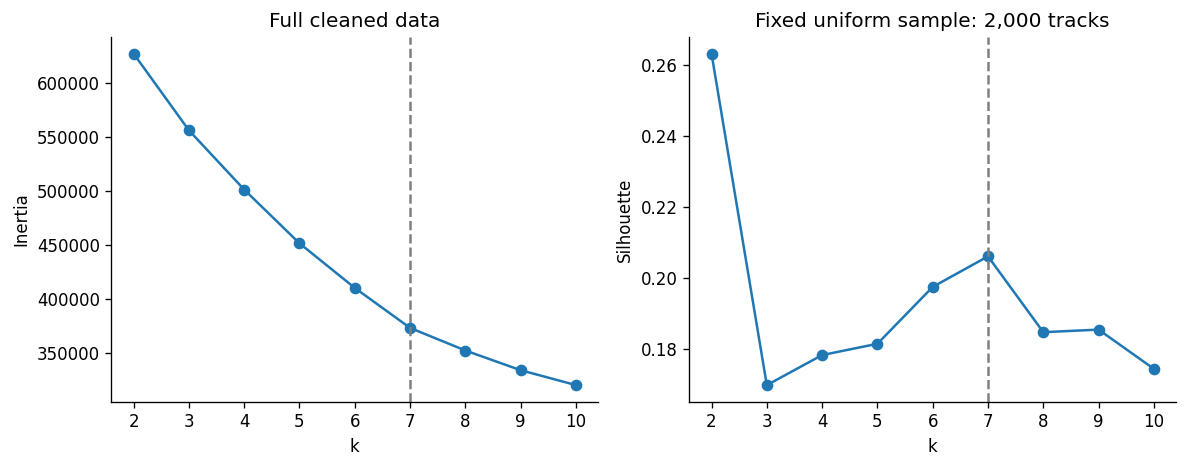

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,0.527326,0.375168,-10.643488,0.054046,0.685718,0.031931,0.160189,0.394017,113.258683
1,0.583399,0.740562,-8.468390,0.072041,0.114926,0.795144,0.169807,0.345247,126.872951
2,0.471060,0.816863,-5.342210,0.085925,0.076273,0.036743,0.195209,0.371245,140.181441
3,0.349216,0.170630,-21.263236,0.052096,0.869132,0.785014,0.156344,0.183957,104.758087
4,0.572082,0.675292,-11.237978,0.847126,0.748982,0.007197,0.671108,0.440950,100.890186
5,0.704983,0.716755,-6.541348,0.096155,0.220612,0.020416,0.164443,0.698440,118.153113
6,0.519664,0.752306,-7.100074,0.088618,0.290081,0.077682,0.743794,0.502999,123.365426


,tracks
0,17986
1,10027
2,19861
3,6450
4,1038
5,27354
6,6142


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,-0.201764,-1.014812,-0.416100,-0.296022,1.054912,-0.436445,-0.289647,-0.288669,-0.303135
1,0.118586,0.411548,0.002062,-0.138187,-0.631083,1.922785,-0.241134,-0.474718,0.154897
2,-0.525605,0.710887,0.605327,-0.015371,-0.745927,-0.420640,-0.108671,-0.378021,0.604718
3,-1.217987,-1.814145,-2.462656,-0.313286,1.597371,1.891123,-0.309464,-1.089925,-0.588933
4,0.052738,0.157370,-0.530759,6.687274,1.242223,-0.512827,2.341522,-0.110585,-0.719239
5,0.809363,0.320357,0.374855,0.074732,-0.320168,-0.471991,-0.267629,0.869391,-0.137352
6,-0.246225,0.458024,0.266368,0.007953,-0.114032,-0.294534,2.716094,0.125608,0.036912


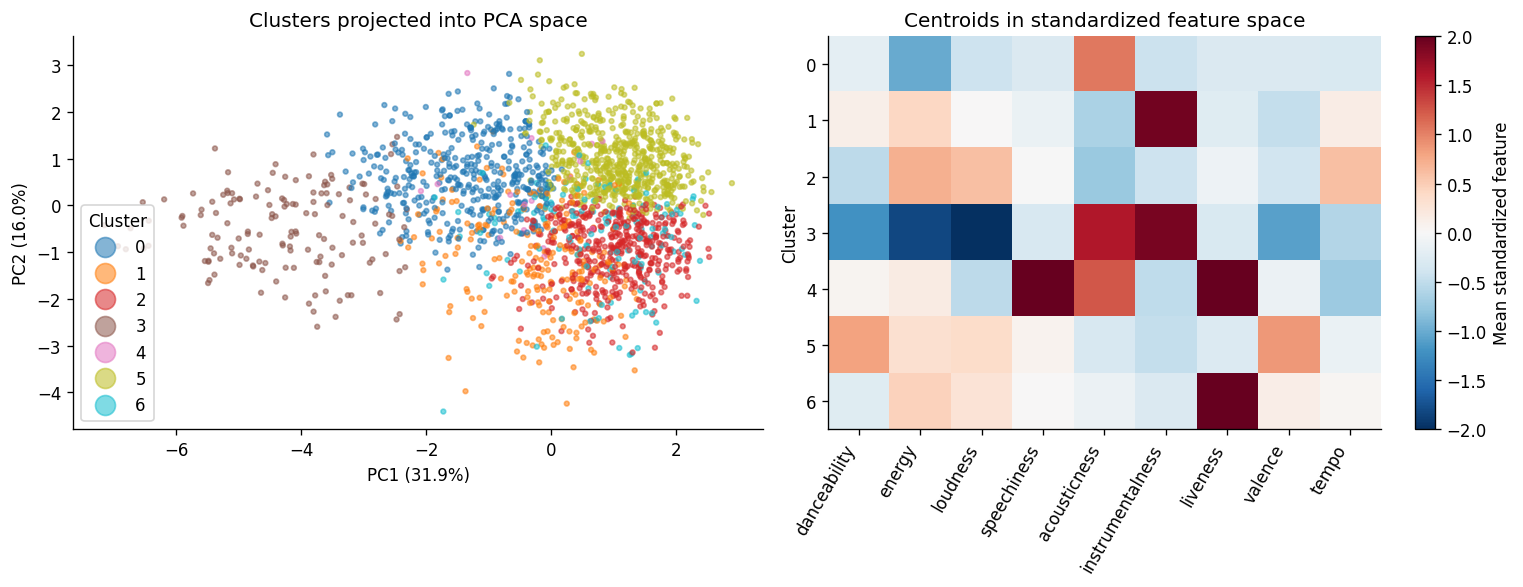

In [9]:
K_VALUES = list(range(2,11))
sil_idx = rng.choice(len(clean),size=min(2000,len(clean)),replace=False)
models, k_rows = {}, []
for k in K_VALUES:
    model=KMeans(n_clusters=k,n_init=10,random_state=SEED,algorithm='lloyd').fit(Z)
    score=silhouette_score(Z[sil_idx],model.labels_[sil_idx])
    models[k]=model
    k_rows.append([k,model.inertia_,score,model.n_iter_])
    print(f'k={k}: inertia={model.inertia_:.1f}, silhouette={score:.4f}')
k_metrics=pd.DataFrame(k_rows,columns=['k','inertia','silhouette','iterations']).set_index('k')
k_metrics['relative_inertia_reduction']=1-k_metrics.inertia/k_metrics.inertia.shift(1)
table('kmeans_selection',k_metrics)
# Choose k=7 using the inertia elbow and the local silhouette peak.
BEST_K=7
kmeans=models[BEST_K]
cluster_labels=kmeans.labels_
print('Chosen k by elbow and local silhouette peak:',BEST_K)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(k_metrics.index,k_metrics.inertia,'o-');axes[0].set(xlabel='k',ylabel='Inertia',title='Full cleaned data')
axes[1].plot(k_metrics.index,k_metrics.silhouette,'o-');axes[1].set(xlabel='k',ylabel='Silhouette',title='Fixed uniform sample: 2,000 tracks')
for ax in axes: ax.axvline(BEST_K,color='gray',linestyle='--')
fig.tight_layout();figure('kmeans_k_selection',fig)
cluster_profiles=clean[AUDIO].assign(cluster=cluster_labels).groupby('cluster').mean()
table('track_cluster_profiles_raw',cluster_profiles)
table('track_cluster_counts',pd.Series(cluster_labels).value_counts().sort_index().to_frame('tracks'))
cluster_z=pd.DataFrame(kmeans.cluster_centers_,columns=AUDIO,index=cluster_profiles.index)
table('track_cluster_profiles_standardized',cluster_z)
fig,axes=plt.subplots(1,2,figsize=(13,5))
scatter=axes[0].scatter(pcs[sil_idx,0],pcs[sil_idx,1],c=cluster_labels[sil_idx],cmap='tab10',s=8,alpha=.55)
axes[0].set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
            ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})',title='Clusters projected into PCA space')
handles,_=scatter.legend_elements();axes[0].legend(handles,[str(i) for i in range(BEST_K)],title='Cluster',markerscale=2)
im=axes[1].imshow(cluster_z,cmap='RdBu_r',vmin=-2,vmax=2,aspect='auto')
axes[1].set_xticks(range(len(AUDIO)),AUDIO,rotation=60,ha='right')
axes[1].set_yticks(range(BEST_K),[str(i) for i in range(BEST_K)])
axes[1].set(ylabel='Cluster',title='Centroids in standardized feature space')
fig.colorbar(im,ax=axes[1],label='Mean standardized feature')
fig.tight_layout();figure('track_clusters_pca_profiles',fig)

## Section 5.3: Stability and collection effects
Two independent uniform subsamples (20,000 tracks each) refit both the scaler and
k-means. They assign the same full reference tracks. Adjusted Rand index (ARI)
is invariant to cluster names; Hungarian label matching additionally reports the
fraction of changed assignments. Sampling, duplicate weights and PCA projection
provide distinct checks. Genre labels are never inputs to individual-track clustering.

In [10]:
def matched_change(a,b,k):
    counts=np.zeros((k,k),dtype=int)
    np.add.at(counts,(a,b),1)
    rows,cols=linear_sum_assignment(-counts)
    return 1-counts[rows,cols].sum()/len(a)

stability=[]
sub_predictions=[]
for run in range(2):
    idx=rng.choice(len(clean),size=min(20000,len(clean)),replace=False)
    ss=StandardScaler().fit(clean.iloc[idx][AUDIO])
    km=KMeans(n_clusters=BEST_K,n_init=10,random_state=SEED).fit(ss.transform(clean.iloc[idx][AUDIO]))
    pred=km.predict(ss.transform(clean[AUDIO]));sub_predictions.append(pred)
    stability.append([f'uniform_subsample_{run+1}',len(idx),
                      adjusted_rand_score(cluster_labels,pred),matched_change(cluster_labels,pred,BEST_K)])
stability.append(['subsample_1_vs_2',min(20000,len(clean)),
                  adjusted_rand_score(*sub_predictions),matched_change(*sub_predictions,BEST_K)])
# Sensitivity check retaining cleaned song-genre listings; invalid/conflicting rows stay excluded.
listing_scaler=StandardScaler().fit(valid_rows[AUDIO])
listing_model=KMeans(n_clusters=BEST_K,n_init=10,random_state=SEED).fit(listing_scaler.transform(valid_rows[AUDIO]))
listing_prediction=listing_model.predict(listing_scaler.transform(clean[AUDIO]))
stability.append(['duplicate_listing_weight_sensitivity',len(valid_rows),
                  adjusted_rand_score(cluster_labels,listing_prediction),
                  matched_change(cluster_labels,listing_prediction,BEST_K)])
table('cluster_stability',pd.DataFrame(stability,columns=['check','fit_rows','ARI','matched_changed_fraction']).set_index('check'))

genre_cluster=memberships.merge(clean[['track_id']].assign(cluster=cluster_labels),on='track_id',validate='many_to_one')
genre_cluster['weight']=1/genre_cluster.groupby('track_id').track_genre.transform('size')
cross=genre_cluster.pivot_table(index='track_genre',columns='cluster',values='weight',aggfunc='sum',fill_value=0)
table('genre_cluster_weighted_counts',cross,show=False)
table('genre_cluster_proportions',cross.div(cross.sum(axis=1),axis=0),show=False)
top_genres=[]
for c in cross:
    frac=cross[c]/cross[c].sum()
    for g in frac.nlargest(5).index:
        top_genres.append([c,g,float(frac[g]),float(cross.loc[g,c]/cross.loc[g].sum())])
table('cluster_top_genre_memberships',pd.DataFrame(top_genres,columns=['cluster','genre','share_of_cluster','share_of_genre']))
manifest['chosen_k']=BEST_K
manifest['silhouette_sample_size']=len(sil_idx)
manifest['geometry_features']=AUDIO

,fit_rows,ARI,matched_changed_fraction
check,,,
uniform_subsample_1,20000,0.958163,0.015058
uniform_subsample_2,20000,0.979119,0.007911
subsample_1_vs_2,20000,0.959872,0.015328
duplicate_listing_weight_sensitivity,111458,0.967714,0.012346


,cluster,genre,share_of_cluster,share_of_genre
0,0,tango,0.043562,0.783892
1,0,honky-tonk,0.041560,0.762366
2,0,romance,0.038641,0.769657
3,0,cantopop,0.035333,0.677505
4,0,show-tunes,0.032136,0.611640
5,1,detroit-techno,0.073734,0.759979
6,1,minimal-techno,0.067543,0.861057
7,1,study,0.059440,0.597194
8,1,grindcore,0.051694,0.522865
9,1,idm,0.049417,0.498491


## Section 6: Recording groups and held-out evaluation
One row per track ID prevents repeated-genre leakage. A stricter grouping also
joins equal normalized artist/title pairs and identical full audio/musical payloads
across IDs (possible reissues). Connected components are kept together. No popularity
value is used to define groups. Missing artist/title pairs use their unique track ID.
GroupShuffleSplit with the student-ID seed holds out approximately 20% for test;
another 20% of development groups is validation. The same split is used for both
targets. Scalers, encoders, artist categories and model selection see training data only.
PCA and clustering are descriptive and are not used as regression preprocessing.

In [11]:
def normalized_text(s):
    return s.str.normalize('NFKC').str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip()

identity_keys = pd.DataFrame({'artists': normalized_text(clean.artists),
                              'track_name': normalized_text(clean.track_name)})
identity_complete = identity_keys.artists.ne('') & identity_keys.track_name.ne('')
parent = np.arange(len(clean))
def find_root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def join_indices(indices):
    first = int(indices[0])
    for j in indices[1:]:
        a,b=find_root(first),find_root(int(j))
        if a != b:
            parent[max(a,b)] = min(a,b)

identity_original_indices = identity_keys.index[identity_complete].to_numpy()
for indices in identity_keys.loc[identity_complete].groupby(['artists','track_name'],sort=False).indices.values():
    # GroupBy.indices refers to positions in the filtered frame, not original row indices.
    original_indices = identity_original_indices[indices]
    if len(original_indices)>1:
        join_indices(original_indices)
for indices in clean.groupby(AUDIO+CAT,sort=False).indices.values():
    if len(indices)>1:
        join_indices(indices)
groups = np.array([find_root(i) for i in range(len(clean))])
clean['recording_group'] = groups
group_counts=pd.Series(groups).value_counts()
table('audit_related_recording_groups',pd.DataFrame({
    'count': [len(clean),len(group_counts),int(group_counts.gt(1).sum()),
              int(group_counts[group_counts.gt(1)].sum()),int(group_counts.max())]},
    index=['unique_track_ids','recording_groups','groups_with_multiple_ids',
           'tracks_in_multiple_id_groups','largest_group_tracks']))

splitter=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED)
dev_idx,test_idx=next(splitter.split(clean,groups=groups))
inner=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED)
tr_pos,val_pos=next(inner.split(clean.iloc[dev_idx],groups=groups[dev_idx]))
train_idx,val_idx=dev_idx[tr_pos],dev_idx[val_pos]
for a,b in [(train_idx,val_idx),(train_idx,test_idx),(val_idx,test_idx)]:
    assert not set(groups[a]) & set(groups[b])
    assert not set(clean.iloc[a].track_id) & set(clean.iloc[b].track_id)
split_labels=np.full(len(clean),'train',dtype=object)
split_labels[val_idx]='validation';split_labels[test_idx]='test'
table('split_track_ids',clean[['track_id','recording_group']].assign(split=split_labels),show=False)
split_sizes=pd.DataFrame([
    [name,len(idx),len(np.unique(groups[idx])),len(idx)/len(clean)]
    for name,idx in [('train',train_idx),('validation',val_idx),('development',dev_idx),('test',test_idx)]],
    columns=['split','tracks','recording_groups','fraction']).set_index('split')
table('regression_split_sizes',split_sizes)
manifest['splits']=split_sizes.to_dict(orient='index')
manifest['split_policy']='Connected recording groups; 20% test groups and 20% of remaining groups for validation'

,count
unique_track_ids,88858
recording_groups,80147
groups_with_multiple_ids,4913
tracks_in_multiple_id_groups,13624
largest_group_tracks,45


,tracks,recording_groups,fraction
split,,,
train,56931,51293,0.640696
validation,14158,12824,0.159333
development,71089,64117,0.800029
test,17769,16030,0.199971


### Q1/Q2: Ordinary linear regression and training-mean baseline
Q1/Q2 use all allowed predictors, with one-hot musical categories (first category
dropped to avoid redundant intercept columns). Energy is an additional predictor
only for popularity. Both OLS and the mean baseline fit all development data.
RMSE is in target units; RMSE/baseline and R-squared allow comparison across scales.
Confidence intervals resample whole held-out recording groups, not repeated tracks.

,coefficient
numeric__danceability,-0.035185
numeric__speechiness,0.029138
numeric__acousticness,-0.108278
numeric__instrumentalness,0.037002
numeric__liveness,0.028290
numeric__valence,0.040757
numeric__loudness,0.136533
numeric__tempo,0.007224
musical_categories__key_1,0.015952
musical_categories__key_2,0.003414


,coefficient
numeric__danceability,1.658380
numeric__speechiness,-1.284998
numeric__acousticness,-0.352999
numeric__instrumentalness,-3.021422
numeric__liveness,0.050433
numeric__valence,-2.158455
numeric__loudness,0.560211
numeric__tempo,0.233714
numeric__energy,-0.714014
musical_categories__key_1,0.112688


,preregistered_rmse,OLS_test_rmse,mean_baseline_test_rmse,actual_minus_predicted_rmse,rmse_divided_by_baseline,relative_rmse_reduction,test_r_squared,rmse_group_CI_low,rmse_group_CI_high,training_target_mean
target,,,,,,,,,,
energy,0.12,0.122288,0.256880,0.002288,0.476050,0.523950,0.773338,0.120178,0.124558,0.635672
popularity,18.00,20.200150,20.498428,2.200150,0.985449,0.014551,0.028797,19.934403,20.447464,33.202422


,energy,popularity
danceability,0.131246,0.065679
energy,1.000000,0.014541
loudness,0.759097,0.075635
speechiness,0.138935,-0.048179
acousticness,-0.733551,-0.039340
instrumentalness,-0.177228,-0.132253
liveness,0.196583,-0.015162
valence,0.247254,-0.012291
tempo,0.248862,0.009313
popularity,0.014541,1.000000


,count,mean,std,min,25%,50%,75%,max
energy,71089.0,0.635672,0.255778,0.00002,0.459,0.677,0.854,1.0
popularity,71089.0,33.202422,20.569679,0.00000,19.000,33.000,49.000,99.0


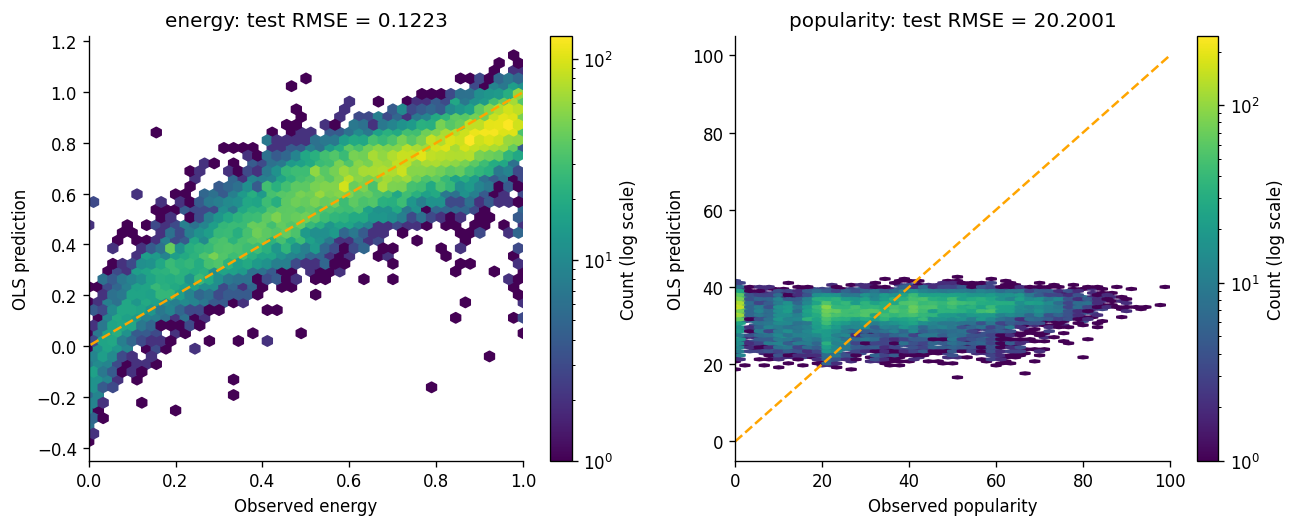

In [12]:
def audio_preprocessor(target, sparse=False):
    numeric=NUM+(['energy'] if target=='popularity' else [])
    return ColumnTransformer([
        ('numeric',StandardScaler(),numeric),
        ('musical_categories',OneHotEncoder(drop='first',handle_unknown='ignore',
                                           sparse_output=sparse),CAT)],
        sparse_threshold=1.0 if sparse else 0.0)

def group_bootstrap_rmse(y,pred,g,n_boot=500):
    t=pd.DataFrame({'group':g,'sq':(np.asarray(y)-np.asarray(pred))**2})
    a=t.groupby('group').sq.agg(['sum','size']).to_numpy()
    brng=np.random.default_rng(SEED)
    rmses=[]
    for _ in range(n_boot):
        chosen=brng.integers(0,len(a),size=len(a))
        sample=a[chosen].sum(axis=0)
        rmses.append(np.sqrt(sample[0]/sample[1]))
    return np.quantile(rmses,[.025,.975])

ols_models,ols_predictions,reg_rows={}, {}, []
for target in ['energy','popularity']:
    inputs=BASE_INPUTS+(['energy'] if target=='popularity' else [])
    assert target not in inputs
    assert not set(inputs)&{'duration_ms','explicit','track_genre','track_id','artists','album_name','track_name'}
    ols=Pipeline([('preprocess',audio_preprocessor(target)),('model',LinearRegression())])
    ydev=clean.iloc[dev_idx][target];ytest=clean.iloc[test_idx][target]
    ols.fit(clean.iloc[dev_idx][inputs],ydev)
    pred=ols.predict(clean.iloc[test_idx][inputs])
    baseline=DummyRegressor(strategy='mean').fit(clean.iloc[dev_idx][inputs],ydev)
    basepred=baseline.predict(clean.iloc[test_idx][inputs])
    error=root_mean_squared_error(ytest,pred)
    baseerror=root_mean_squared_error(ytest,basepred)
    lo,hi=group_bootstrap_rmse(ytest,pred,groups[test_idx])
    reg_rows.append([target,PRE_RMSE[target],error,baseerror,error-PRE_RMSE[target],
                     error/baseerror,1-error/baseerror,r2_score(ytest,pred),lo,hi,float(ydev.mean())])
    ols_models[target]=ols;ols_predictions[target]=pred
    table('ols_coefficients_'+target,pd.DataFrame({'coefficient':ols.named_steps['model'].coef_},
          index=ols.named_steps['preprocess'].get_feature_names_out()))
regression_results=pd.DataFrame(reg_rows,columns=['target','preregistered_rmse','OLS_test_rmse',
    'mean_baseline_test_rmse','actual_minus_predicted_rmse','rmse_divided_by_baseline',
    'relative_rmse_reduction','test_r_squared','rmse_group_CI_low','rmse_group_CI_high','training_target_mean']).set_index('target')
table('regression_results',regression_results)
correlations=clean.iloc[dev_idx][AUDIO+['popularity']].corr()[['energy','popularity']]
table('regression_target_correlations_development',correlations)
table('regression_target_distributions',clean.iloc[dev_idx][['energy','popularity']].describe().T)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,target in zip(axes,['energy','popularity']):
    y=clean.iloc[test_idx][target].to_numpy();pred=ols_predictions[target]
    im=ax.hexbin(y,pred,gridsize=45,mincnt=1,bins='log',cmap='viridis')
    lim=[min(y.min(),pred.min()),max(y.max(),pred.max())]
    ax.plot(lim,lim,'--',color='orange');ax.set(xlabel='Observed '+target,ylabel='OLS prediction',
        title=f'{target}: test RMSE = {regression_results.loc[target,"OLS_test_rmse"]:.4f}')
    ax.set_xlim((0,1) if target=='energy' else (0,100))
    fig.colorbar(im,ax=ax,label='Count (log scale)')
fig.tight_layout();figure('regression_test_predictions',fig)

### Q3: One additional dataset column, artists
Use the literal `artists` string as one additional column (collaborations remain
their original strings). A train-fitted one-hot encoder groups categories appearing
fewer than five times. Audio-only and audio-plus-artists Ridge models use the same
fixed alpha=10, the same development data and test groups. Seen/unseen artist
performance is reported separately. This estimates catalog association, not a
causal artist effect or performance for completely unseen artists.

,tracks,audio_only_rmse,audio_plus_artists_rmse,rmse_reduction
test_subset,,,,
all,17769,20.200182,17.875529,2.324653
seen_artist_string,12668,19.921661,16.536319,3.385342
unseen_artist_string,5101,20.875803,20.832255,0.043548


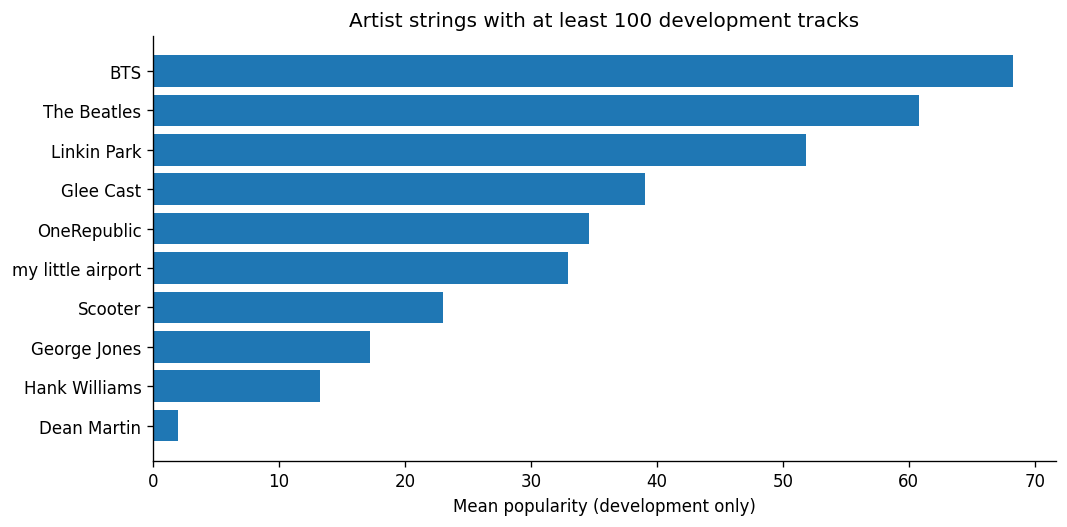

In [13]:
artist_pre=ColumnTransformer([
    ('numeric',StandardScaler(),NUM+['energy']),
    ('musical_categories',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=True),CAT),
    ('artists',OneHotEncoder(min_frequency=5,handle_unknown='infrequent_if_exist',sparse_output=True),['artists'])],
    sparse_threshold=1.0)
artist_model=Pipeline([('preprocess',artist_pre),('model',Ridge(alpha=10,solver='lsqr',tol=1e-6))])
audio_ridge=Pipeline([('preprocess',audio_preprocessor('popularity',sparse=True)),
                      ('model',Ridge(alpha=10,solver='lsqr',tol=1e-6))])
for model in [artist_model,audio_ridge]:
    model.fit(clean.iloc[dev_idx],clean.iloc[dev_idx].popularity)
artist_pred=artist_model.predict(clean.iloc[test_idx])
audio_ridge_pred=audio_ridge.predict(clean.iloc[test_idx])
seen=clean.iloc[test_idx].artists.isin(set(clean.iloc[dev_idx].artists)).to_numpy()
artist_results=[]
for name,mask in [('all',np.ones(len(test_idx),dtype=bool)),('seen_artist_string',seen),('unseen_artist_string',~seen)]:
    if mask.sum():
        actual=clean.iloc[test_idx].popularity.to_numpy()[mask]
        aerr=root_mean_squared_error(actual,audio_ridge_pred[mask])
        berr=root_mean_squared_error(actual,artist_pred[mask])
        artist_results.append([name,int(mask.sum()),aerr,berr,aerr-berr])
table('additional_artist_information',pd.DataFrame(artist_results,columns=['test_subset','tracks',
      'audio_only_rmse','audio_plus_artists_rmse','rmse_reduction']).set_index('test_subset'))
artist_means=clean.iloc[dev_idx].groupby('artists').popularity.agg(['count','mean','std'])
frequent=artist_means.query('count >= 100').sort_values('mean',ascending=False)
table('artist_popularity_development',frequent,show=False)
show=frequent.head(10).sort_values('mean')
fig,ax=plt.subplots(figsize=(9,4.5))
ax.barh(show.index,show['mean']);ax.set(xlabel='Mean popularity (development only)',title='Artist strings with at least 100 development tracks')
fig.tight_layout();figure('artist_popularity',fig)

## Section 6 Q4: correlated polynomial inputs and regularization
Target: energy. Source columns: loudness, acousticness, instrumentalness, all from the allowed audio list (Spec pp. 8–9). No target or external variable is an input.

Use the degree-3 polynomial basis allowed by Q4's richer-basis setting. The model is linear in its 19 basis coefficients. Identify acousticness, acousticness² and acousticness³ as three mutually correlated inputs, using training-only Pearson correlations. Standardize each basis column using only the fitting subset. The full and 80-track settings use exactly the same basis so their difference is training size.

Alpha is selected using validation RMSE only. The full-data model is then refit on development; the small model remains fit on its fixed 80 training groups. OLS uses identical inputs and fitting rows as Ridge. All 25 strengths are shown, without choosing a strength from test outcomes. 

In [14]:
# Q4: correlated polynomial inputs on the full development dataset.
# Use only the three permitted audio columns. The basis is fixed before
# validation/test evaluation; alpha is selected by validation RMSE alone.
q4_features = ['loudness', 'acousticness', 'instrumentalness']
assert set(q4_features).issubset(BASE_INPUTS) and 'energy' not in q4_features
q4_alphas = np.logspace(-6, 6, 25)
q4_correlated_names = ['acousticness', 'acousticness^2', 'acousticness^3']

def q4_pipeline(alpha=None):
    return Pipeline([
        ('basis', PolynomialFeatures(degree=3, include_bias=False)),
        ('scale_basis', StandardScaler()),
        ('model', LinearRegression() if alpha is None else Ridge(alpha=alpha, solver='svd'))])

q4_basis = PolynomialFeatures(degree=3, include_bias=False)
q4_train_basis = q4_basis.fit_transform(clean.iloc[train_idx][q4_features])
q4_basis_names = q4_basis.get_feature_names_out(q4_features)
q4_train_corr = pd.DataFrame(q4_train_basis, columns=q4_basis_names).corr()
q4_correlations = []
for first, second in itertools.combinations(q4_correlated_names, 2):
    r = float(q4_train_corr.loc[first, second])
    q4_correlations.append([first, second, r, abs(r)])
q4_corr_evidence = pd.DataFrame(q4_correlations,
    columns=['feature_1', 'feature_2', 'training_pearson_r', 'absolute_r'])
assert q4_corr_evidence.absolute_r.gt(.90).all()
table('ridge_correlated_training_evidence', q4_corr_evidence)

# Uniformly draw 80 distinct training recording groups, one representative track each.
# The fixed RNG stream follows the silhouette and stability samples; no outcome-based resampling.
representatives = clean.iloc[train_idx].drop_duplicates('recording_group').index.to_numpy()
q4_small_idx = rng.choice(representatives, size=80, replace=False)
table('q4_final_small_training_ids', clean.iloc[q4_small_idx][['track_id', 'recording_group']], show=False)
assert len(q4_small_idx) == 80
assert len(set(groups[q4_small_idx])) == 80
assert not set(groups[q4_small_idx]) & set(groups[val_idx])
assert not set(groups[q4_small_idx]) & set(groups[test_idx])
q4_small_basis = q4_basis.transform(clean.iloc[q4_small_idx][q4_features])
q4_small_corr = pd.DataFrame(q4_small_basis, columns=q4_basis_names).corr()
q4_small_evidence = pd.DataFrame([
    [a, b, float(q4_small_corr.loc[a,b]), abs(float(q4_small_corr.loc[a,b]))]
    for a,b in itertools.combinations(q4_correlated_names,2)],
    columns=['feature_1','feature_2','training_pearson_r','absolute_r'])
assert q4_small_evidence.absolute_r.gt(.90).all()
table('ridge_correlated_small_training_evidence', q4_small_evidence)

q4_summary_rows = []
for setting, fit_indices in [('full_polynomial', dev_idx), ('small_polynomial', q4_small_idx)]:
    selection_indices = train_idx if setting == 'full_polynomial' else q4_small_idx
    validation_errors = []
    for alpha in q4_alphas:
        model = q4_pipeline(float(alpha)).fit(clean.iloc[selection_indices][q4_features],
                                             clean.iloc[selection_indices].energy)
        validation_errors.append(root_mean_squared_error(clean.iloc[val_idx].energy,
            model.predict(clean.iloc[val_idx][q4_features])))
    selected_alpha = float(q4_alphas[int(np.argmin(validation_errors))])
    rows = []; coefficient_rows = {}
    for alpha, validation_error in zip(q4_alphas, validation_errors):
        model = q4_pipeline(float(alpha)).fit(clean.iloc[fit_indices][q4_features],
                                             clean.iloc[fit_indices].energy)
        prediction = model.predict(clean.iloc[test_idx][q4_features])
        coefficients = model.named_steps['model'].coef_
        assert np.isfinite(prediction).all()
        representative = [float(coefficients[list(q4_basis_names).index(name)])
                          for name in q4_correlated_names]
        rows.append([float(alpha), float(validation_error),
            root_mean_squared_error(clean.iloc[test_idx].energy,prediction),
            float(np.linalg.norm(coefficients)),
            root_mean_squared_error(clean.iloc[fit_indices].energy, model.predict(clean.iloc[fit_indices][q4_features])), *representative])
        coefficient_rows[float(alpha)] = coefficients
    path = pd.DataFrame(rows, columns=['alpha','validation_rmse','test_rmse',
        'coefficient_l2', 'training_rmse', *q4_correlated_names]).set_index('alpha')
    assert np.all(np.diff(path.coefficient_l2) <= 1e-8)
    table('ridge_correlated_'+setting+'_path', path)
    table('ridge_correlated_'+setting+'_coefficients',
        pd.DataFrame(coefficient_rows, index=q4_basis_names), show=False)
    ols = q4_pipeline().fit(clean.iloc[fit_indices][q4_features], clean.iloc[fit_indices].energy)
    ols_rmse = root_mean_squared_error(clean.iloc[test_idx].energy,
        ols.predict(clean.iloc[test_idx][q4_features]))
    chosen_rmse = float(path.loc[selected_alpha,'test_rmse'])
    q4_summary_rows.append([setting,len(fit_indices),len(q4_basis_names),selected_alpha,
        ols_rmse,chosen_rmse,ols_rmse-chosen_rmse])

q4_summary = pd.DataFrame(q4_summary_rows,columns=['setting','training_tracks','basis_features',
    'alpha_selected_on_validation','OLS_test_rmse','selected_Ridge_test_rmse',
    'test_rmse_improvement']).set_index('setting')
table('ridge_correlated_summary',q4_summary)
manifest['q4_correlated_basis'] = {
    'source_columns':q4_features,'polynomial_degree':3,
    'basis_count':len(q4_basis_names),'training_only_correlated_basis':q4_correlated_names,
    'full_selected_alpha':float(q4_summary.loc['full_polynomial','alpha_selected_on_validation']),
    'small_selected_alpha':float(q4_summary.loc['small_polynomial','alpha_selected_on_validation'])}
(OUT/'reproducibility.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('Q4 correlated-input experiments completed; validation-only alpha selection.')


,feature_1,feature_2,training_pearson_r,absolute_r
0,acousticness,acousticness^2,0.964570,0.964570
1,acousticness,acousticness^3,0.912905,0.912905
2,acousticness^2,acousticness^3,0.986535,0.986535


,feature_1,feature_2,training_pearson_r,absolute_r
0,acousticness,acousticness^2,0.961438,0.961438
1,acousticness,acousticness^3,0.900169,0.900169
2,acousticness^2,acousticness^3,0.983462,0.983462


,validation_rmse,test_rmse,coefficient_l2,training_rmse,acousticness,acousticness^2,acousticness^3
alpha,,,,,,,
0.000001,0.130215,0.128638,0.797740,0.128851,-0.216645,0.439931,-0.312063
0.000003,0.130215,0.128638,0.797740,0.128851,-0.216645,0.439931,-0.312063
0.000010,0.130215,0.128638,0.797740,0.128851,-0.216645,0.439931,-0.312063
0.000032,0.130215,0.128638,0.797740,0.128851,-0.216645,0.439931,-0.312063
0.000100,0.130215,0.128638,0.797739,0.128851,-0.216645,0.439930,-0.312062
0.000316,0.130215,0.128638,0.797737,0.128851,-0.216644,0.439929,-0.312062
0.001000,0.130215,0.128638,0.797730,0.128851,-0.216643,0.439925,-0.312059
0.003162,0.130215,0.128638,0.797707,0.128851,-0.216640,0.439913,-0.312050
0.010000,0.130215,0.128638,0.797637,0.128851,-0.216631,0.439876,-0.312022


,validation_rmse,test_rmse,coefficient_l2,training_rmse,acousticness,acousticness^2,acousticness^3
alpha,,,,,,,
0.000001,0.180317,0.181215,3.971350,0.118106,-0.426124,0.825914,-0.777070
0.000003,0.180311,0.181208,3.970382,0.118106,-0.426137,0.825933,-0.777001
0.000010,0.180291,0.181185,3.967327,0.118106,-0.426177,0.825992,-0.776783
0.000032,0.180231,0.181112,3.957717,0.118106,-0.426303,0.826178,-0.776092
0.000100,0.180044,0.180887,3.927834,0.118107,-0.426689,0.826741,-0.773908
0.000316,0.179498,0.180229,3.838098,0.118115,-0.427796,0.828300,-0.767007
0.001000,0.178112,0.178566,3.594307,0.118176,-0.430346,0.831376,-0.745453
0.003162,0.175553,0.175534,3.074939,0.118533,-0.432523,0.829865,-0.683037
0.010000,0.172644,0.172150,2.353024,0.119732,-0.420203,0.790340,-0.543058


,training_tracks,basis_features,alpha_selected_on_validation,OLS_test_rmse,selected_Ridge_test_rmse,test_rmse_improvement
setting,,,,,,
full_polynomial,71089,19,1.000000,0.128638,0.128637,0.000001
small_polynomial,80,19,3.162278,0.181219,0.145732,0.035487


Q4 correlated-input experiments completed; validation-only alpha selection.


## Report evidence and figures
Plots below use the already fitted models and exported tables. No additional selection or outcome-based sample search is performed.

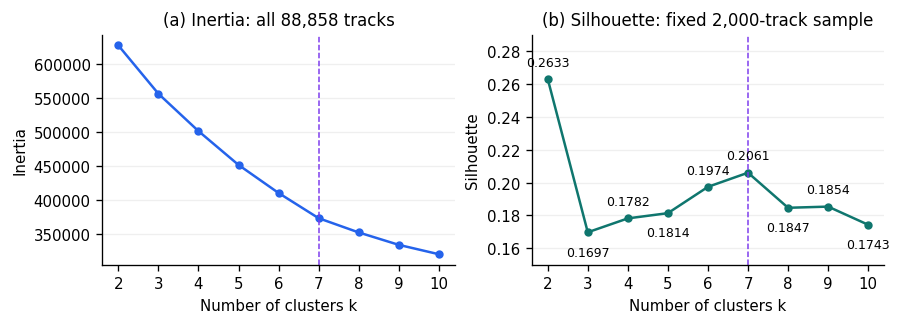

,PC1,PC2
cluster,,
0,-1.318184,0.646797
1,-0.171225,-1.095304
2,0.979968,-0.982667
3,-4.223498,-0.447866
4,0.102777,0.466134
5,1.045281,0.946960
6,0.733451,-0.754184


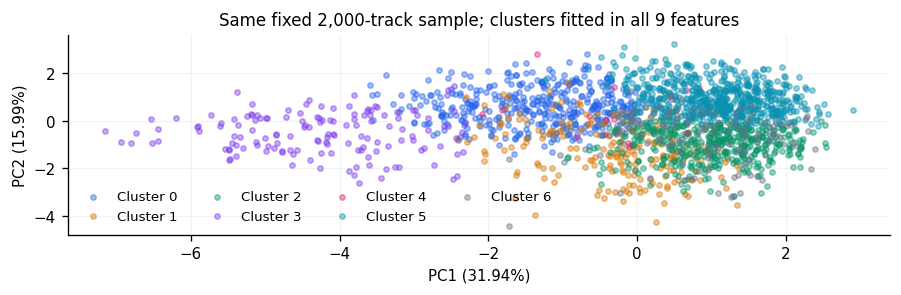

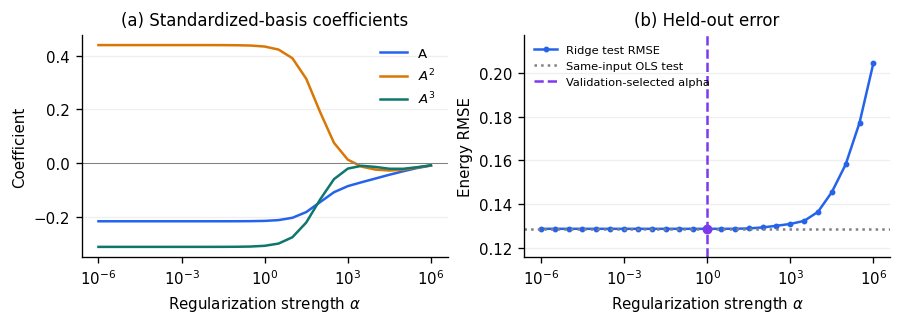

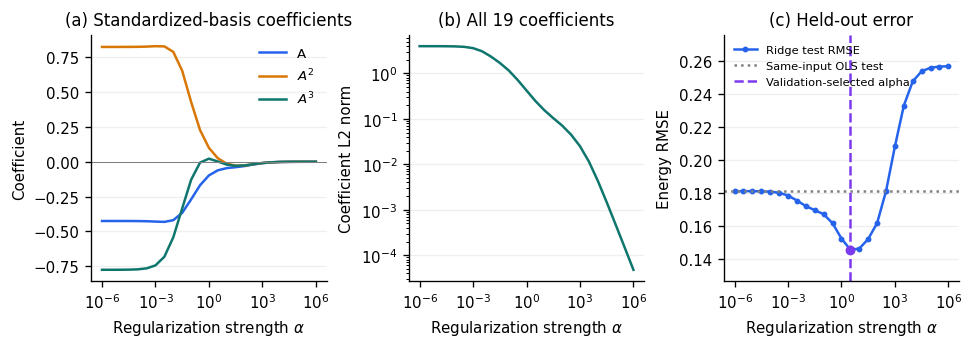

In [15]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.titlesize': 10, 'axes.labelsize': 9, 'legend.fontsize': 8,
    'axes.spines.top': False, 'axes.spines.right': False, 'savefig.dpi': 300})
BLUE, ORANGE, TEAL, PURPLE = '#2563eb', '#d97706', '#0f766e', '#7c3aed'
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.6), layout='constrained')
for ax, column, title, color in zip(axes, ['inertia', 'silhouette'],
    ['(a) Inertia: all 88,858 tracks', '(b) Silhouette: fixed 2,000-track sample'], [BLUE, TEAL]):
    values = k_metrics[column]
    ax.plot(k_metrics.index, values, 'o-', color=color, linewidth=1.5, markersize=4)
    ax.axvline(BEST_K, color=PURPLE, linestyle='--', linewidth=.9)
    ax.set(title=title, xlabel='Number of clusters k', ylabel=column.capitalize(), xticks=K_VALUES)
    ax.grid(axis='y', alpha=.2)
    if column == 'silhouette':
        ax.set_ylim(.15, .29)
        for k, value in values.items():
            ax.annotate(f'{value:.4f}', (k, value), xytext=(0, -14 if k in [3,5,8,10] else 8),
                        textcoords='offset points', ha='center', fontsize=7.5)
figure('report_k_selection', fig)

fig, ax = plt.subplots(figsize=(7.4, 2.35), layout='constrained')
for c, color in enumerate([BLUE, ORANGE, '#059669', PURPLE, '#db2777', '#0891b2', '#64748b']):
    mask = cluster_labels[sil_idx] == c
    ax.scatter(pcs[sil_idx[mask],0], pcs[sil_idx[mask],1], s=10, alpha=.42,
               color=color, label=f'Cluster {c}')
projected_centroids = pd.DataFrame(pcs[:,:2], columns=['PC1','PC2']).assign(cluster=cluster_labels).groupby('cluster').mean()
table('cluster_pca_centroids', projected_centroids)
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.2%})',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.2%})', title='Same fixed 2,000-track sample; clusters fitted in all 9 features')
ax.legend(frameon=False, ncol=4); ax.grid(alpha=.15)
figure('report_cluster_pca', fig)

alpha_ticks = [1e-6, 1e-3, 1, 1e3, 1e6]
for setting, name in [('full_polynomial','report_q4_full'), ('small_polynomial','report_q4_small')]:
    path = pd.read_csv(OUT/f'ridge_correlated_{setting}_path.csv').set_index('alpha')
    summary = q4_summary.loc[setting]
    assert float(path.validation_rmse.idxmin()) == float(summary.alpha_selected_on_validation)
    small = setting == 'small_polynomial'
    fig, axes = plt.subplots(1, 3 if small else 2, figsize=(8,2.8) if small else (7.4,2.6), layout='constrained')
    for name_basis, label, color in zip(q4_correlated_names, ['A', r'$A^2$', r'$A^3$'], [BLUE, ORANGE, TEAL]):
        axes[0].plot(path.index, path[name_basis], label=label, color=color, linewidth=1.5)
    axes[0].axhline(0, color='gray', linewidth=.6)
    axes[0].set(title='(a) Standardized-basis coefficients', ylabel='Coefficient')
    axes[0].legend(frameon=False)
    if small:
        axes[1].plot(path.index, path.coefficient_l2, color=TEAL)
        axes[1].set(title='(b) All 19 coefficients', ylabel='Coefficient L2 norm', yscale='log')
    ax = axes[-1]
    ax.plot(path.index, path.test_rmse, 'o-', color=BLUE, markersize=2.5, label='Ridge test RMSE')
    ax.axhline(summary.OLS_test_rmse, color='gray', linestyle=':', label='Same-input OLS test')
    ax.axvline(summary.alpha_selected_on_validation, color=PURPLE, linestyle='--', label='Validation-selected alpha')
    ax.scatter([summary.alpha_selected_on_validation], [summary.selected_Ridge_test_rmse], color=PURPLE, s=24, zorder=5)
    ax.set(title='(c) Held-out error' if small else '(b) Held-out error', ylabel='Energy RMSE')
    ax.legend(frameon=False, fontsize=6.8); ax.margins(y=.17)
    for ax in axes:
        ax.set(xscale='log', xlabel=r'Regularization strength $\alpha$', xticks=alpha_ticks)
        ax.grid(axis='y', alpha=.2)
    figure(name, fig)


## Final reproducibility checks

In [16]:
assert clean.track_id.is_unique
assert len(train_idx) + len(val_idx) + len(test_idx) == len(clean)
assert set(train_idx) | set(val_idx) == set(dev_idx)
for target in ['energy', 'popularity']:
    assert np.isfinite(ols_predictions[target]).all()
    assert np.isclose(regression_results.loc[target, 'training_target_mean'], clean.iloc[dev_idx][target].mean())
    expected = BASE_INPUTS if target == 'energy' else BASE_INPUTS + ['energy']
    assert set(ols_models[target].named_steps['preprocess'].feature_names_in_) == set(expected)
assert set(q4_features).issubset(BASE_INPUTS)
assert q4_corr_evidence.absolute_r.min() > .90
assert q4_small_evidence.absolute_r.min() > .90
manifest['final_review'] = {'fresh_kernel_checks': True, 'q4_basis_same_in_full_and_small': True,
    'validation_only_alpha_selection': True}
(OUT/'reproducibility.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
print('All computational checks passed. All final results reproduced from tracks.csv.')


All computational checks passed. All final results reproduced from tracks.csv.
